## 4-6_Optimizing_the_ridge_regression_parameter

In [1]:
## 1. Generate regression data and fit RidgeCV with candidate alpha values.

import numpy as np

from sklearn.datasets import make_regression
reg_data, reg_target = make_regression(n_samples=100, n_features=2, effective_rank=1, noise=10)

from sklearn.linear_model import RidgeCV
rcv = RidgeCV(alphas=np.array([.1, .2, .3, .4]))
rcv.fit(reg_data, reg_target)

,"alphas alphas: array-like of shape (n_alphas,), default=(0.1, 1.0, 10.0)Array of alpha values to try.Regularization strength; must be a positive float. Regularizationimproves the conditioning of the problem and reduces the variance ofthe estimates. Larger values specify stronger regularization.Alpha corresponds to ``1 / (2C)`` in other linear models such as:class:`~sklearn.linear_model.LogisticRegression` or:class:`~sklearn.svm.LinearSVC`.If using Leave-One-Out cross-validation, alphas must be strictly positive.","array([0.1, 0.2, 0.3, 0.4])"
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"scoring scoring: str, callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: negative :ref:`mean squared error ` if cv is None (i.e. when using leave-one-out cross-validation), or :ref:`coefficient of determination ` (:math:`R^2`) otherwise.",None
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the efficient Leave-One-Out cross-validation- integer, to specify the number of folds.- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used, else,:class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here.",None
,"gcv_mode gcv_mode: {'auto', 'svd', 'eigen'}, default='auto'Flag indicating which strategy to use when performingLeave-One-Out Cross-Validation. Options are:: 'auto' : use 'svd' if n_samples > n_features, otherwise use 'eigen' 'svd' : force use of singular value decomposition of X when X is dense, eigenvalue decomposition of X^T.X when X is sparse. 'eigen' : force computation via eigendecomposition of X.X^TThe 'auto' mode is the default and is intended to pick the cheaperoption of the two depending on the shape of the training data.",None
,"store_cv_results store_cv_results: bool, default=FalseFlag indicating if the cross-validation values corresponding toeach alpha should be stored in the ``cv_results_`` attribute (seebelow). This flag is only compatible with ``cv=None`` (i.e. usingLeave-One-Out Cross-Validation)... versionchanged:: 1.5 Parameter name changed from `store_cv_values` to `store_cv_results`.",False
,"alpha_per_target alpha_per_target: bool, default=FalseFlag indicating whether to optimize the alpha value (picked from the`alphas` parameter list) for each target separately (for multi-outputsettings: multiple prediction targets). When set to `True`, afterfitting, the `alpha_` attribute will contain a value for each target.When set to `False`, a single alpha is used for all targets... versionadded:: 0.24",False


In [4]:
## 2. Display the optimal alpha selected by RidgeCV.

rcv.alpha_

0.1

In [5]:
## 3. Refine the alpha search range and display the selected value.

rcv2 = RidgeCV(alphas=np.array([.08, .09, .1, .11, .12]))
rcv2.fit(reg_data, reg_target)
rcv2.alpha_

0.08

In [6]:
## 4. Fit RidgeCV over a wider range of alpha values.

alphas_to_test = np.linspace(0.01, 1)
rcv3 = RidgeCV(alphas=alphas_to_test, store_cv_results=True)
rcv3.fit(reg_data, reg_target)

,"alphas alphas: array-like of shape (n_alphas,), default=(0.1, 1.0, 10.0)Array of alpha values to try.Regularization strength; must be a positive float. Regularizationimproves the conditioning of the problem and reduces the variance ofthe estimates. Larger values specify stronger regularization.Alpha corresponds to ``1 / (2C)`` in other linear models such as:class:`~sklearn.linear_model.LogisticRegression` or:class:`~sklearn.svm.LinearSVC`.If using Leave-One-Out cross-validation, alphas must be strictly positive.","array([0.01 ..., 1. ])"
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"scoring scoring: str, callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: negative :ref:`mean squared error ` if cv is None (i.e. when using leave-one-out cross-validation), or :ref:`coefficient of determination ` (:math:`R^2`) otherwise.",None
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the efficient Leave-One-Out cross-validation- integer, to specify the number of folds.- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used, else,:class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here.",None
,"gcv_mode gcv_mode: {'auto', 'svd', 'eigen'}, default='auto'Flag indicating which strategy to use when performingLeave-One-Out Cross-Validation. Options are:: 'auto' : use 'svd' if n_samples > n_features, otherwise use 'eigen' 'svd' : force use of singular value decomposition of X when X is dense, eigenvalue decomposition of X^T.X when X is sparse. 'eigen' : force computation via eigendecomposition of X.X^TThe 'auto' mode is the default and is intended to pick the cheaperoption of the two depending on the shape of the training data.",None
,"store_cv_results store_cv_results: bool, default=FalseFlag indicating if the cross-validation values corresponding toeach alpha should be stored in the ``cv_results_`` attribute (seebelow). This flag is only compatible with ``cv=None`` (i.e. usingLeave-One-Out Cross-Validation)... versionchanged:: 1.5 Parameter name changed from `store_cv_values` to `store_cv_results`.",True
,"alpha_per_target alpha_per_target: bool, default=FalseFlag indicating whether to optimize the alpha value (picked from the`alphas` parameter list) for each target separately (for multi-outputsettings: multiple prediction targets). When set to `True`, afterfitting, the `alpha_` attribute will contain a value for each target.When set to `False`, a single alpha is used for all targets... versionadded:: 0.24",False


In [7]:
## 5. Check the shape of the cross-validation results.

rcv3.cv_results_.shape

(100, 50)

In [8]:
## 6. Find the alpha value with the smallest mean cross-validation error.

smallest_idx = rcv3.cv_results_.mean(axis=0).argmin()
alphas_to_test[smallest_idx]

np.float64(0.01)

In [9]:
## 7. Display the optimal alpha selected by RidgeCV.

rcv3.alpha_

0.01

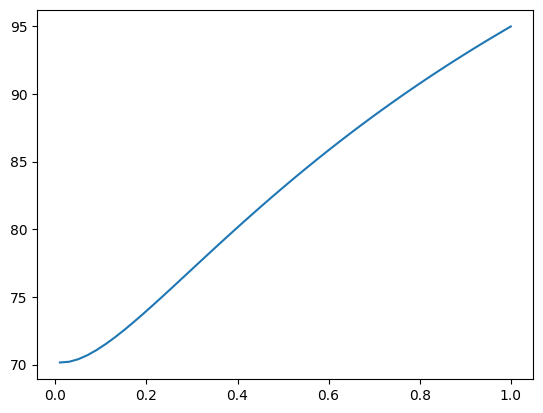

In [11]:
## 8. Plot the mean cross-validation error for each alpha.
import matplotlib.pyplot as plt
%matplotlib inline
plt.plot(alphas_to_test, rcv3.cv_results_.mean(axis=0))

In [12]:
## 9. Optimize ridge regression using mean absolute error.

from sklearn.metrics import mean_absolute_error

from sklearn.metrics import make_scorer
MAD_scorer = make_scorer(mean_absolute_error, greater_is_better=False)

rcv4 = RidgeCV(alphas=alphas_to_test, store_cv_results=True, scoring=MAD_scorer)
rcv4.fit(reg_data, reg_target)
smallest_idx = rcv4.cv_results_.mean(axis=0).argmin()

In [13]:
## 10. Display the mean cross-validation score at the selected index.

rcv4.cv_results_.mean(axis=0)[smallest_idx]

np.float64(-1.356801471719229)

In [14]:
## 11. Display the alpha value at the selected index.

alphas_to_test[smallest_idx]

np.float64(1.0)

In [15]:
## 12. Generate noisy linear data and fit a Bayesian ridge regression model.

X = np.linspace(0, 5)
y_truth = 3 * X
y_noise = np.random.normal(0, 0.5, len(y_truth)) #normally distributed noise with mean 0 and spread 0.1
y_noisy = (y_truth + y_noise)


from sklearn.linear_model import BayesianRidge
br_inst = BayesianRidge().fit(X.reshape(-1, 1), y_noisy)

<ErrorbarContainer object of 3 artists>

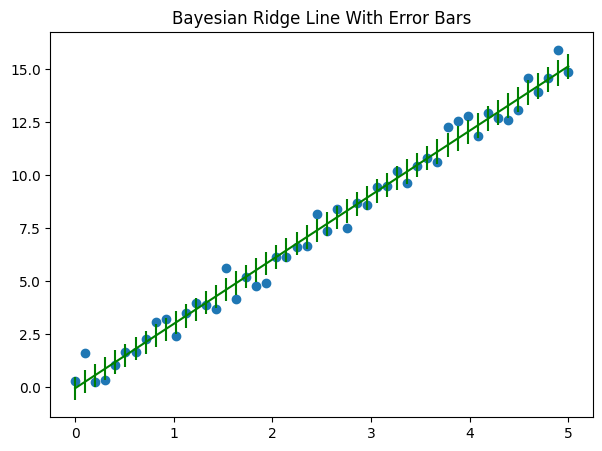

In [16]:
## 13. Visualize Bayesian ridge predictions with error bars.

y_pred, y_err = br_inst.predict(X.reshape(-1, 1), return_std=True)

plt.figure(figsize=(7, 5))
plt.scatter(X, y_noisy)
plt.title("Bayesian Ridge Line With Error Bars")
plt.errorbar(X, y_pred, y_err, color='green')

<ErrorbarContainer object of 3 artists>

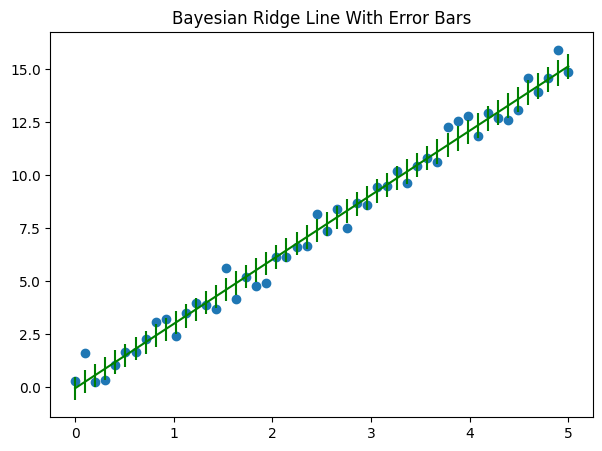

In [17]:
## 14. Repeat the Bayesian ridge prediction plot.

y_pred, y_err = br_inst.predict(X.reshape(-1, 1), return_std=True)

plt.figure(figsize=(7, 5))
plt.scatter(X, y_noisy)
plt.title("Bayesian Ridge Line With Error Bars")
plt.errorbar(X, y_pred, y_err, color='green')